# ferreus_rbf capability review and SciPy comparison

This notebook focuses on the interpolation stage: turning scattered observations `(x, y, z, value)` into a continuous scalar field. It deliberately does not extract a mesh or export to geoh5; those are separate downstream concerns already covered by the RMT proof-of-concept notebooks.

The goals are to:

1. compare `ferreus_rbf.RBFInterpolator` with `scipy.interpolate.RBFInterpolator` using the same observations and equivalent settings;
2. measure fit time, repeated-evaluation time, and interpolation accuracy;
3. test Ferreus gradient output against a field with a known analytical gradient; and
4. record which geological constraints the public Python API can and cannot accept.

> Benchmark numbers are machine- and version-specific. The reproducible method and the trends are more important than one timing value.

In [1]:
from importlib.metadata import PackageNotFoundError, version
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
from ferreus_rbf import RBFInterpolator as FerreusRBFInterpolator
from ferreus_rbf.interpolant_config import (
    Drift,
    InterpolantSettings,
    RBFKernelType,
)
from scipy.interpolate import RBFInterpolator as ScipyRBFInterpolator


def installed_version(distribution_name: str) -> str:
    try:
        return version(distribution_name)
    except PackageNotFoundError:
        return "unknown"


print("ferreus-rbf:", installed_version("ferreus-rbf"))
print("SciPy:", installed_version("scipy"))
print("NumPy:", installed_version("numpy"))

ferreus-rbf: 0.2.2
SciPy: 1.17.1
NumPy: 2.4.6


## 1. What is being compared?

An RBF interpolator receives scattered points and a scalar value at each point. It solves for a continuous function `f(x, y, z)` that can be evaluated at new locations. In implicit geological modelling, an isosurface is a set of locations where that function has one chosen value, for example, `f = 0`.

This notebook uses a synthetic folded horizon because its true field is known everywhere:

`f(x, y, z) = z - [20 sin(x / 35) + 10 cos(y / 40)]`

The `f = 0` isosurface is the folded horizon. Positive values are above it and negative values are below it. Because the exact function and gradient are known, errors can be measured objectively. A real dataset is useful later, but usually does not provide this ground truth.

In [2]:
# Axis-aligned domain: [xmin, ymin, zmin, xmax, ymax, zmax].
MODEL_EXTENTS = np.array(
    [-100.0, -100.0, -60.0, 100.0, 100.0, 60.0],
    dtype=np.float64,
)


def true_horizon_elevation(x: np.ndarray, y: np.ndarray) -> np.ndarray:
    """Elevation of the synthetic folded horizon."""
    return 20.0 * np.sin(x / 35.0) + 10.0 * np.cos(y / 40.0)


def true_geological_field(points: np.ndarray) -> np.ndarray:
    """Signed vertical separation from the folded horizon."""
    points = np.asarray(points, dtype=np.float64)
    return points[:, 2] - true_horizon_elevation(points[:, 0], points[:, 1])


def true_geological_gradient(points: np.ndarray) -> np.ndarray:
    """Analytical [df/dx, df/dy, df/dz] for the synthetic field."""
    points = np.asarray(points, dtype=np.float64)
    gradients = np.empty_like(points)
    gradients[:, 0] = -(20.0 / 35.0) * np.cos(points[:, 0] / 35.0)
    gradients[:, 1] = +(10.0 / 40.0) * np.sin(points[:, 1] / 40.0)
    gradients[:, 2] = 1.0
    return gradients

## 2. Reproducible source and validation points

The source points are the observations given to each interpolator. The validation points are withheld locations used only to measure predictions. Every method receives exactly the same points and values.

The samples are nested: the 400-point case uses the first 400 points from the same array used by the larger cases. This prevents different random spatial coverage from being mistaken for a package difference.

In [3]:
RANDOM_SEED = 1_234_567

# Set this to True only
# when you intentionally want the longer, repeated benchmark up to 32,000 points.
# You can also remote the 32000 point option as it takes a much longer time than other sizes.
RUN_FULL_BENCHMARK = True
QUICK_SOURCE_COUNTS = (400, 1_000, 2_000)
FULL_SOURCE_COUNTS = (400, 1_000, 2_000, 4_431, 8_000, 16_000, 32_000)
SOURCE_COUNTS = FULL_SOURCE_COUNTS if RUN_FULL_BENCHMARK else QUICK_SOURCE_COUNTS
VALIDATION_COUNT = 2_000 if RUN_FULL_BENCHMARK else 1_000
BENCHMARK_REPETITIONS = 3 if RUN_FULL_BENCHMARK else 1
SOURCE_CHECK_COUNT = 500

rng = np.random.default_rng(RANDOM_SEED)
all_source_points = rng.uniform(
    low=MODEL_EXTENTS[:3],
    high=MODEL_EXTENTS[3:],
    size=(max(SOURCE_COUNTS), 3),
).astype(np.float64)
all_source_values = true_geological_field(all_source_points).astype(np.float64)

validation_points = rng.uniform(
    low=MODEL_EXTENTS[:3],
    high=MODEL_EXTENTS[3:],
    size=(VALIDATION_COUNT, 3),
).astype(np.float64)
validation_true_values = true_geological_field(validation_points).astype(np.float64)

print("Benchmark mode:", "full" if RUN_FULL_BENCHMARK else "quick")
print("Source counts:", SOURCE_COUNTS)
print("Repetitions per source count:", BENCHMARK_REPETITIONS)
print("Largest source set:", all_source_points.shape)
print("Independent validation set:", validation_points.shape)
print("Source value range:", all_source_values.min(), "to", all_source_values.max())

Benchmark mode: full
Source counts: (400, 1000, 2000, 4431, 8000, 16000, 32000)
Repetitions per source count: 3
Largest source set: (32000, 3)
Independent validation set: (2000, 3)
Source value range: -89.57780187730064 to 87.24698324807645


## 3. Matched interpolation settings

A fair comparison requires equivalent mathematical settings:

| Concept | Ferreus | SciPy |
|---|---|---|
| RBF kernel | `RBFKernelType.Linear` | `kernel="linear"` |
| Polynomial trend | `Drift.Linear` | `degree=1` |
| Smoothing | `nugget=0.0` | `smoothing=0.0` |

These are equivalent modelling choices, although their solvers and internal numerical approximations need not be identical.

Ferreus has a separate `build_evaluator` step that prepares its fast repeated evaluator. It needs the evaluation domain extents. No padding is used here because all source and validation points are known to lie inside `MODEL_EXTENTS`. Ferreus fit, evaluator setup, and evaluation are timed separately.

In [4]:
FERREUS_SETTINGS = InterpolantSettings(
    kernel_type=RBFKernelType.Linear,
    drift=Drift.Linear,
    nugget=0.0,
)


def root_mean_squared_error(predicted: np.ndarray, expected: np.ndarray) -> float:
    """Return the typical prediction error in the same units as the field."""
    residuals = np.asarray(predicted) - np.asarray(expected)
    return float(np.sqrt(np.mean(residuals**2)))


def build_ferreus_model(points: np.ndarray, values: np.ndarray):
    return FerreusRBFInterpolator(
        points=points,
        values=values,
        interpolant_settings=FERREUS_SETTINGS,
    )


def build_scipy_model(points: np.ndarray, values: np.ndarray):
    return ScipyRBFInterpolator(
        points,
        values,
        kernel="linear",
        degree=1,
        smoothing=0.0,
    )


def benchmark_source_count(source_count: int, repetitions: int = 3) -> dict:
    # Use the same nested source subset for both packages.
    points = all_source_points[:source_count]
    values = all_source_values[:source_count]

    ferreus_fit_times = []
    ferreus_setup_times = []
    ferreus_eval_times = []
    scipy_fit_times = []
    scipy_eval_times = []

    # Retain the final models/predictions for accuracy metrics; all repetitions
    # use identical inputs, so timing is the only quantity being aggregated.
    ferreus_model = None
    scipy_model = None
    ferreus_validation_predictions = None
    scipy_validation_predictions = None

    for repetition in range(1, repetitions + 1):
        print(f"  repetition {repetition}/{repetitions}", flush=True)

        print("    Ferreus fit ... ", end="", flush=True)
        start = perf_counter()
        ferreus_model = build_ferreus_model(points, values)
        elapsed = perf_counter() - start
        ferreus_fit_times.append(elapsed)
        print(f"{elapsed:.3f} s", flush=True)

        print("    Ferreus evaluator setup ... ", end="", flush=True)
        start = perf_counter()
        ferreus_model.build_evaluator(MODEL_EXTENTS.copy())
        elapsed = perf_counter() - start
        ferreus_setup_times.append(elapsed)
        print(f"{elapsed:.3f} s", flush=True)

        print("    Ferreus validation evaluation ... ", end="", flush=True)
        start = perf_counter()
        ferreus_validation_predictions = np.asarray(
            ferreus_model.evaluate_targets(validation_points),
            dtype=np.float64,
        ).reshape(-1)
        elapsed = perf_counter() - start
        ferreus_eval_times.append(elapsed)
        print(f"{elapsed:.3f} s", flush=True)

        print("    SciPy fit ... ", end="", flush=True)
        start = perf_counter()
        scipy_model = build_scipy_model(points, values)
        elapsed = perf_counter() - start
        scipy_fit_times.append(elapsed)
        print(f"{elapsed:.3f} s", flush=True)

        print("    SciPy validation evaluation ... ", end="", flush=True)
        start = perf_counter()
        scipy_validation_predictions = np.asarray(
            scipy_model(validation_points),
            dtype=np.float64,
        ).reshape(-1)
        elapsed = perf_counter() - start
        scipy_eval_times.append(elapsed)
        print(f"{elapsed:.3f} s", flush=True)

    # Check a bounded subset. A full N-by-N SciPy source evaluation becomes
    # an expensive secondary calculation at the largest source count.
    source_check_count = min(SOURCE_CHECK_COUNT, source_count)
    source_check_indices = np.linspace(
        0, source_count - 1, source_check_count, dtype=np.int64
    )
    source_check_points = points[source_check_indices]
    source_check_values = values[source_check_indices]

    print(
        f"  source diagnostic ({source_check_count} points) ... ",
        end="",
        flush=True,
    )
    ferreus_source_predictions = np.asarray(
        ferreus_model.evaluate_targets(source_check_points),
        dtype=np.float64,
    ).reshape(-1)
    scipy_source_predictions = np.asarray(
        scipy_model(source_check_points),
        dtype=np.float64,
    ).reshape(-1)
    print("done", flush=True)

    result = {
        "source_count": source_count,
        "ferreus_fit_s": float(np.median(ferreus_fit_times)),
        "ferreus_setup_s": float(np.median(ferreus_setup_times)),
        "ferreus_eval_s": float(np.median(ferreus_eval_times)),
        "scipy_fit_s": float(np.median(scipy_fit_times)),
        "scipy_eval_s": float(np.median(scipy_eval_times)),
        "ferreus_source_rmse": root_mean_squared_error(
            ferreus_source_predictions, source_check_values
        ),
        "scipy_source_rmse": root_mean_squared_error(
            scipy_source_predictions, source_check_values
        ),
        "source_check_count": source_check_count,
        "ferreus_validation_rmse": root_mean_squared_error(
            ferreus_validation_predictions, validation_true_values
        ),
        "scipy_validation_rmse": root_mean_squared_error(
            scipy_validation_predictions, validation_true_values
        ),
        "ferreus_validation_max_abs_error": float(
            np.max(np.abs(ferreus_validation_predictions - validation_true_values))
        ),
        "scipy_validation_max_abs_error": float(
            np.max(np.abs(scipy_validation_predictions - validation_true_values))
        ),
        "between_models_rmse": root_mean_squared_error(
            ferreus_validation_predictions, scipy_validation_predictions
        ),
    }
    result["ferreus_total_s"] = (
        result["ferreus_fit_s"] + result["ferreus_setup_s"] + result["ferreus_eval_s"]
    )
    result["scipy_total_s"] = result["scipy_fit_s"] + result["scipy_eval_s"]
    return result

### Timing method

The small health-check cell below announces every native package call and should finish almost immediately. If it stops, its final printed message identifies the failing operation.

With `RUN_FULL_BENCHMARK = False`, tests up to 2,000 source points, 1,000 validation points, and one repetition. Set `RUN_FULL_BENCHMARK = True` in the data-generation cell to include the 4,431-, 8,000-, 16,000-, and 32,000-point cases, 2,000 validation points, and three repetitions. The larger tiers can help to confirm whether Ferreus stays cheaper than SciPy as N keeps growing.

Source-point RMSE is checked on at most 500 evenly spaced source observations. Evaluating SciPy against all source points requires millions of source-target interactions just for this secondary diagnostic, so foregoing it can save time.

In [5]:
# This isolates basic package calls from the performance benchmark.
health_points = all_source_points[:25]
health_values = all_source_values[:25]
health_targets = validation_points[:5]

print("Health check: Ferreus fit ... ", end="", flush=True)
health_ferreus = build_ferreus_model(health_points, health_values)
print("passed", flush=True)

print("Health check: Ferreus evaluator setup ... ", end="", flush=True)
health_ferreus.build_evaluator(MODEL_EXTENTS.copy())
print("passed", flush=True)

print("Health check: Ferreus evaluation ... ", end="", flush=True)
_ = health_ferreus.evaluate_targets(health_targets)
print("passed", flush=True)

print("Health check: SciPy fit ... ", end="", flush=True)
health_scipy = build_scipy_model(health_points, health_values)
print("passed", flush=True)

print("Health check: SciPy evaluation ... ", end="", flush=True)
_ = health_scipy(health_targets)
print("passed", flush=True)
print("Package health check complete.", flush=True)

Health check: Ferreus fit ... passed
Health check: Ferreus evaluator setup ... passed
Health check: Ferreus evaluation ... passed
Health check: SciPy fit ... passed
Health check: SciPy evaluation ... passed
Package health check complete.


In [6]:
print(
    f"Starting {'full' if RUN_FULL_BENCHMARK else 'quick'} benchmark: "
    f"{BENCHMARK_REPETITIONS} repetition(s), "
    f"{VALIDATION_COUNT:,} validation points",
    flush=True,
)
benchmark_results = []
for source_count in SOURCE_COUNTS:
    print(f"\nBenchmarking N={source_count:,}", flush=True)
    benchmark_results.append(
        benchmark_source_count(source_count, BENCHMARK_REPETITIONS)
    )

print("\nBenchmark complete.", flush=True)

Starting full benchmark: 3 repetition(s), 2,000 validation points

Benchmarking N=400
  repetition 1/3
    Ferreus fit ... 0.006 s
    Ferreus evaluator setup ... 0.032 s
    Ferreus validation evaluation ... 0.007 s
    SciPy fit ... 0.329 s
    SciPy validation evaluation ... 0.016 s
  repetition 2/3
    Ferreus fit ... 0.007 s
    Ferreus evaluator setup ... 0.038 s
    Ferreus validation evaluation ... 0.027 s
    SciPy fit ... 0.140 s
    SciPy validation evaluation ... 0.015 s
  repetition 3/3
    Ferreus fit ... 0.007 s
    Ferreus evaluator setup ... 0.007 s
    Ferreus validation evaluation ... 0.060 s
    SciPy fit ... 0.333 s
    SciPy validation evaluation ... 0.035 s
  source diagnostic (400 points) ... done

Benchmarking N=1,000
  repetition 1/3
    Ferreus fit ... 0.058 s
    Ferreus evaluator setup ... 0.023 s
    Ferreus validation evaluation ... 0.084 s
    SciPy fit ... 0.497 s
    SciPy validation evaluation ... 0.047 s
  repetition 2/3
    Ferreus fit ... 0.099 s
 

In [7]:
print(
    f"{'N':>6}  {'F fit':>9} {'F setup':>9} {'F eval':>9} "
    f"{'S fit':>9} {'S eval':>9} {'F total':>9} {'S total':>9}"
)
for result in benchmark_results:
    print(
        f"{result['source_count']:6d}  "
        f"{result['ferreus_fit_s']:9.4f} "
        f"{result['ferreus_setup_s']:9.4f} "
        f"{result['ferreus_eval_s']:9.4f} "
        f"{result['scipy_fit_s']:9.4f} "
        f"{result['scipy_eval_s']:9.4f} "
        f"{result['ferreus_total_s']:9.4f} "
        f"{result['scipy_total_s']:9.4f}"
    )

print("\nAccuracy on withheld validation points:")
print(
    f"{'N':>6}  {'F val RMSE':>12} {'S val RMSE':>12} "
    f"{'F-S RMSE':>12} {'F max err':>12} {'S max err':>12}"
)
for result in benchmark_results:
    print(
        f"{result['source_count']:6d}  "
        f"{result['ferreus_validation_rmse']:12.6g} "
        f"{result['scipy_validation_rmse']:12.6g} "
        f"{result['between_models_rmse']:12.6g} "
        f"{result['ferreus_validation_max_abs_error']:12.6g} "
        f"{result['scipy_validation_max_abs_error']:12.6g}"
    )

print("\nSampled source-point RMSE (zero means exact interpolation):")
for result in benchmark_results:
    print(
        f"N={result['source_count']} "
        f"(checked {result['source_check_count']}): "
        f"Ferreus={result['ferreus_source_rmse']:.6g}, "
        f"SciPy={result['scipy_source_rmse']:.6g}"
    )

     N      F fit   F setup    F eval     S fit    S eval   F total   S total
   400     0.0066    0.0316    0.0265    0.3288    0.0159    0.0647    0.3447
  1000     0.0791    0.0370    0.0838    0.5948    0.0475    0.1999    0.6423
  2000     0.2379    0.0500    0.0195    0.6687    0.0384    0.3075    0.7071
  4431     0.4028    0.0429    0.0057    0.8395    0.0824    0.4514    0.9219
  8000     0.8167    0.0503    0.0082    2.9935    0.1473    0.8751    3.1408
 16000     3.2487    0.1165    0.0112   16.7181    0.2948    3.3763   17.0129
 32000     5.3382    0.1747    0.0145  116.5930    0.6310    5.5274  117.2241

Accuracy on withheld validation points:
     N    F val RMSE   S val RMSE     F-S RMSE    F max err    S max err
   400      0.914575     0.914575  1.91936e-13      8.27237      8.27237
  1000      0.469391     0.469391  1.19056e-13      5.69145      5.69145
  2000      0.203201       0.2032  9.31322e-06      2.34156      2.34155
  4431      0.097667    0.0976646  3.16029e

### How to read the output

- **Sampled source RMSE**: measures reproduction at up to 500 values used for fitting. With zero smoothing it should be close to zero. The sample bounds the cost of this secondary diagnostic.
- **Validation RMSE**: measures error at unseen locations against the known true field. This is the most useful accuracy number here. Lower is better.
- **F-S RMSE**: measures disagreement between Ferreus and SciPy at the same validation points. A small value means their fields agree, but it does not by itself prove either is accurate; that is why validation RMSE is also needed.
- **Fit**: is model construction. **F setup** is Ferreus fast-evaluator preparation. **Eval** predicts all 2,000 validation values.
- **Total**: is fit plus all required setup plus one evaluation. For workflows with many evaluation batches, compare fit/setup once and evaluation many times rather than relying only on this one-batch total.

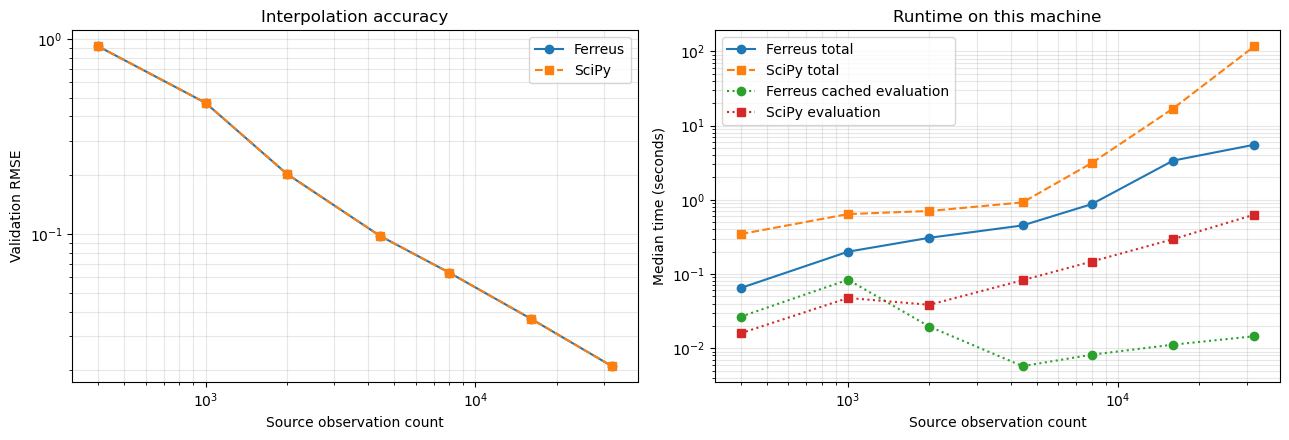

In [8]:
source_counts = np.array([r["source_count"] for r in benchmark_results])
ferreus_validation_rmse = np.array(
    [r["ferreus_validation_rmse"] for r in benchmark_results]
)
scipy_validation_rmse = np.array(
    [r["scipy_validation_rmse"] for r in benchmark_results]
)
ferreus_total_times = np.array([r["ferreus_total_s"] for r in benchmark_results])
scipy_total_times = np.array([r["scipy_total_s"] for r in benchmark_results])
ferreus_eval_times = np.array([r["ferreus_eval_s"] for r in benchmark_results])
scipy_eval_times = np.array([r["scipy_eval_s"] for r in benchmark_results])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].loglog(source_counts, ferreus_validation_rmse, "o-", label="Ferreus")
axes[0].loglog(source_counts, scipy_validation_rmse, "s--", label="SciPy")
axes[0].set_xlabel("Source observation count")
axes[0].set_ylabel("Validation RMSE")
axes[0].set_title("Interpolation accuracy")
axes[0].grid(True, which="both", alpha=0.3)
axes[0].legend()

axes[1].loglog(source_counts, ferreus_total_times, "o-", label="Ferreus total")
axes[1].loglog(source_counts, scipy_total_times, "s--", label="SciPy total")
axes[1].loglog(
    source_counts, ferreus_eval_times, "o:", label="Ferreus cached evaluation"
)
axes[1].loglog(source_counts, scipy_eval_times, "s:", label="SciPy evaluation")
axes[1].set_xlabel("Source observation count")
axes[1].set_ylabel("Median time (seconds)")
axes[1].set_title("Runtime on this machine")
axes[1].grid(True, which="both", alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

## 3.1 Peak memory: process-isolated benchmark at larger N

The timing/accuracy loop above reuses one long-lived kernel process for every method and source count. That is fine for wall-clock time, but it makes peak memory ambiguous: Python's allocator rarely returns freed pages to the OS, so memory freed by an earlier SciPy fit can make a later Ferreus fit look like it uses more memory than it actually needs (or vice versa).

To get a trustworthy per-package number, `rbf_benchmark_worker.py` (in this same folder) runs exactly one method for one source count in a brand-new OS process. It reports the process's peak working set (Windows `peak_wset`, a lifetime-of-process maximum, not just a value sampled at one instant), so a short-lived spike during the linear solve is captured even though `evaluate_targets`/final RSS has since dropped back down.

This section repeats the run for every `(method, source_count)` pair in `SOURCE_COUNTS`, specifically to see whether Ferreus's memory advantage grows, shrinks, or stays flat as N increases.

In [9]:
import json as json_module
import subprocess
import sys
from pathlib import Path


WORKER_SCRIPT = Path.cwd() / "rbf_benchmark_worker.py"
assert WORKER_SCRIPT.exists(), f"Worker script not found: {WORKER_SCRIPT}"

# A single fit is enough per case: peak_wset is a lifetime-of-process
# maximum, so extra repetitions would not change the reported peak.
MEMORY_REPETITIONS = 1
WORKER_TIMEOUT_S = 600


def run_isolated_benchmark(method: str, source_count: int) -> dict:
    """Run one method/source-count case in its own process; parse its JSON result."""
    command = [
        sys.executable,
        str(WORKER_SCRIPT),
        "--method",
        method,
        "--source-count",
        str(source_count),
        "--max-source-count",
        str(max(SOURCE_COUNTS)),
        "--validation-count",
        str(VALIDATION_COUNT),
        "--repetitions",
        str(MEMORY_REPETITIONS),
        "--source-check-count",
        str(SOURCE_CHECK_COUNT),
        "--random-seed",
        str(RANDOM_SEED),
    ]
    completed = subprocess.run(
        command,
        capture_output=True,
        text=True,
        timeout=WORKER_TIMEOUT_S,
        check=True,
    )
    return json_module.loads(completed.stdout)

In [10]:
memory_results = []
for source_count in SOURCE_COUNTS:
    for method in ("ferreus", "scipy"):
        print(
            f"Isolated run: method={method:>8}, N={source_count:6,} ... ",
            end="",
            flush=True,
        )
        result = run_isolated_benchmark(method, source_count)
        memory_results.append(result)
        print(
            f"fit={result['fit_s']:8.3f} s, "
            f"peak added={result['peak_added_memory_mb']:9.1f} MB",
            flush=True,
        )

print("\nIsolated peak-memory benchmark complete.")

Isolated run: method= ferreus, N=   400 ... fit=   0.004 s, peak added=     17.1 MB
Isolated run: method=   scipy, N=   400 ... fit=   0.024 s, peak added=     42.3 MB
Isolated run: method= ferreus, N= 1,000 ... fit=   0.032 s, peak added=     19.4 MB
Isolated run: method=   scipy, N= 1,000 ... fit=   0.055 s, peak added=     46.4 MB
Isolated run: method= ferreus, N= 2,000 ... fit=   0.184 s, peak added=     65.9 MB
Isolated run: method=   scipy, N= 2,000 ... fit=   0.279 s, peak added=     71.3 MB
Isolated run: method= ferreus, N= 4,431 ... fit=   0.348 s, peak added=    177.9 MB
Isolated run: method=   scipy, N= 4,431 ... fit=   0.530 s, peak added=    195.5 MB
Isolated run: method= ferreus, N= 8,000 ... fit=   0.698 s, peak added=    220.8 MB
Isolated run: method=   scipy, N= 8,000 ... fit=   2.214 s, peak added=    538.7 MB
Isolated run: method= ferreus, N=16,000 ... fit=   2.550 s, peak added=    278.1 MB
Isolated run: method=   scipy, N=16,000 ... fit=  15.952 s, peak added=   20

In [11]:
print(
    f"{'N':>6}  {'method':>8}  {'fit_s':>9}  "
    f"{'peak_added_MB':>14}  {'peak_total_MB':>14}"
)
for result in memory_results:
    print(
        f"{result['source_count']:6d}  "
        f"{result['method']:>8}  "
        f"{result['fit_s']:9.4f}  "
        f"{result['peak_added_memory_mb']:14.1f}  "
        f"{result['peak_memory_mb']:14.1f}"
    )

largest_n = max(SOURCE_COUNTS)
ferreus_largest = next(
    r
    for r in memory_results
    if r["method"] == "ferreus" and r["source_count"] == largest_n
)
scipy_largest = next(
    r
    for r in memory_results
    if r["method"] == "scipy" and r["source_count"] == largest_n
)
print(
    f"\nAt N={largest_n:,}: SciPy used "
    f"{scipy_largest['peak_added_memory_mb'] / max(ferreus_largest['peak_added_memory_mb'], 1e-9):.1f}x "
    "the peak memory and "
    f"{scipy_largest['fit_s'] / max(ferreus_largest['fit_s'], 1e-9):.1f}x "
    "the fit time of Ferreus (isolated-process measurement)."
)

     N    method      fit_s   peak_added_MB   peak_total_MB
   400   ferreus     0.0039            17.1            57.4
   400     scipy     0.0244            42.3            82.7
  1000   ferreus     0.0320            19.4            58.9
  1000     scipy     0.0548            46.4            86.8
  2000   ferreus     0.1836            65.9           106.3
  2000     scipy     0.2791            71.3           111.0
  4431   ferreus     0.3482           177.9           217.5
  4431     scipy     0.5304           195.5           235.3
  8000   ferreus     0.6980           220.8           261.1
  8000     scipy     2.2138           538.7           578.5
 16000   ferreus     2.5501           278.1           317.9
 16000     scipy    15.9524          2010.9          2051.6
 32000   ferreus     5.6299           550.4           590.6
 32000     scipy   152.7915          7887.7          7928.2

At N=32,000: SciPy used 14.3x the peak memory and 27.1x the fit time of Ferreus (isolated-process m

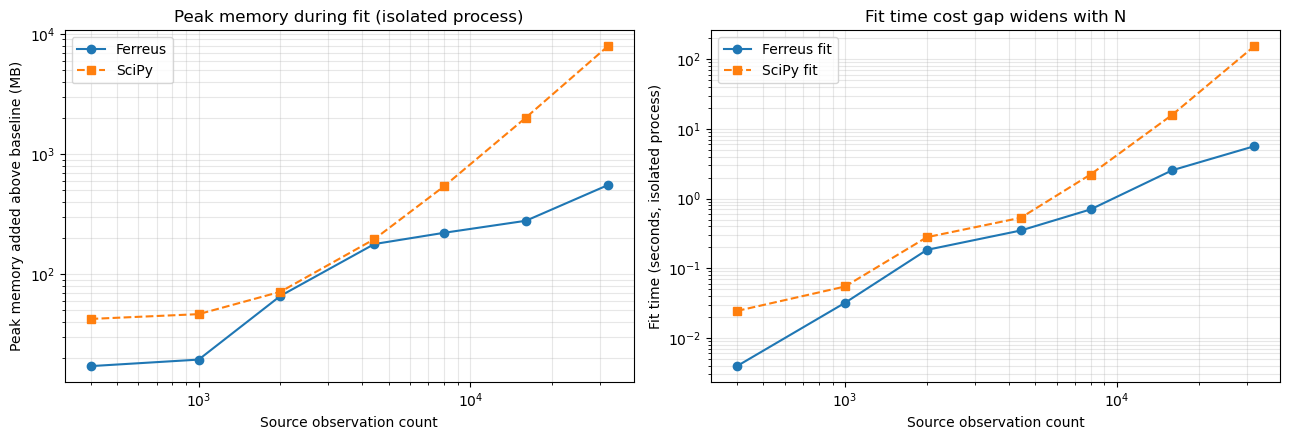

In [12]:
memory_source_counts = sorted({r["source_count"] for r in memory_results})


def _series(method: str, key: str) -> list[float]:
    return [
        next(
            r[key]
            for r in memory_results
            if r["method"] == method and r["source_count"] == n
        )
        for n in memory_source_counts
    ]


ferreus_peak_memory_mb = _series("ferreus", "peak_added_memory_mb")
scipy_peak_memory_mb = _series("scipy", "peak_added_memory_mb")
ferreus_isolated_fit_s = _series("ferreus", "fit_s")
scipy_isolated_fit_s = _series("scipy", "fit_s")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].loglog(memory_source_counts, ferreus_peak_memory_mb, "o-", label="Ferreus")
axes[0].loglog(memory_source_counts, scipy_peak_memory_mb, "s--", label="SciPy")
axes[0].set_xlabel("Source observation count")
axes[0].set_ylabel("Peak memory added above baseline (MB)")
axes[0].set_title("Peak memory during fit (isolated process)")
axes[0].grid(True, which="both", alpha=0.3)
axes[0].legend()

axes[1].loglog(memory_source_counts, ferreus_isolated_fit_s, "o-", label="Ferreus fit")
axes[1].loglog(memory_source_counts, scipy_isolated_fit_s, "s--", label="SciPy fit")
axes[1].set_xlabel("Source observation count")
axes[1].set_ylabel("Fit time (seconds, isolated process)")
axes[1].set_title("Fit time cost gap widens with N")
axes[1].grid(True, which="both", alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

### How to read the peak-memory output

- **peak_added_MB**: the process's peak working set minus its baseline (post-import, pre-fit) working set. This isolates the cost of the fit itself from fixed interpreter/library overhead.
- **peak_total_MB**: the absolute peak working set, useful for sizing a machine or container.
- Both packages solve a dense linear system, so both are expected to need more memory per source point as N grows; the question this section answers is how the two costs compare at the same N, and whether that gap changes at larger N.
- Because each case runs in its own process, these fit times are a second, independent measurement of the cost gap (compare against the `Runtime on this machine` chart above, which reuses one process for all cases).

## 4. Public Python capability review

The table distinguishes observations accepted during fitting from quantities that can be calculated after fitting. That distinction is essential for geological constraints.

| Capability | `ferreus_rbf` 0.2.2 | SciPy `RBFInterpolator` | Tested here? |
|---|---|---|---|
| Fit scalar values at scattered 3-D points | Yes | Yes | Yes |
| Linear RBF plus linear polynomial trend | Yes | Yes | Yes |
| Smoothing (`nugget` / `smoothing`) | Yes | Yes | Zero-smoothing case only |
| Reuse a fitted model for many target points | Yes; optional fast evaluator | Yes | Yes |
| Return field gradients | Yes, directly | No direct public gradient method | Ferreus tested below |
| Native global trend / anisotropy control | `global_trend` argument | Usually pre-transform coordinates manually | Not yet tested |
| Contact/value equality, e.g. `f(p) = 0` | Yes, as ordinary scalar values | Yes, as ordinary scalar values | Synthetic values tested |
| Orientation/gradient **input** observations | Not exposed by public fitting constructor | Not exposed | No |
| Inequality input, e.g. `f(p) > 0` | Not exposed | Not exposed | No |

The final two rows are API limitations, not necessarily evidence that RBF mathematics cannot represent those ideas. A wrapper could convert some geological knowledge into additional scalar pseudo-observations, but that introduces more modelling choices and would require valiation of some kind.

## 5. Ferreus gradient-output test

A gradient is a three-component vector `[df/dx, df/dy, df/dz]`. It points in the direction where the scalar field increases fastest. On an isosurface it is normal (perpendicular) to the local surface, so its direction can be compared with geological orientation information.

Here, Ferreus predicts gradients from a model fitted only to scalar values. We compare those predicted gradients with the analytical gradient of the known synthetic field.

> This tests gradient output. (It does not show that measured normal vectors can be supplied as orientation constraints during fitting)

In [13]:
gradient_source_count = max(SOURCE_COUNTS)
gradient_model = build_ferreus_model(
    all_source_points[:gradient_source_count],
    all_source_values[:gradient_source_count],
)
gradient_model.build_evaluator(MODEL_EXTENTS.copy())

predicted_values, predicted_gradients = gradient_model.evaluate_targets_with_gradients(
    validation_points
)
predicted_values = np.asarray(predicted_values, dtype=np.float64).reshape(-1)
predicted_gradients = np.asarray(predicted_gradients, dtype=np.float64)
expected_gradients = true_geological_gradient(validation_points)

gradient_component_rmse = root_mean_squared_error(
    predicted_gradients, expected_gradients
)
gradient_vector_errors = np.linalg.norm(
    predicted_gradients - expected_gradients, axis=1
)

# Angular error ignores vector magnitude and measures direction agreement.
denominator = np.linalg.norm(predicted_gradients, axis=1) * np.linalg.norm(
    expected_gradients, axis=1
)
cosine_similarity = (
    np.sum(predicted_gradients * expected_gradients, axis=1) / denominator
)
gradient_angle_errors_degrees = np.degrees(
    np.arccos(np.clip(cosine_similarity, -1.0, 1.0))
)

print(
    "Value RMSE from gradient evaluation:",
    root_mean_squared_error(predicted_values, validation_true_values),
)
# On average, how far off each of the 3 gradient components (df/dx, df/dy, df/dz) is from the true value.
print("Gradient component RMSE:", gradient_component_rmse)
# Average length of the error vector (predicted gradient - true gradient)
print("Mean gradient-vector error:", float(np.mean(gradient_vector_errors)))
# Average angular difference between predicted and true gradient directions, ignoring magnitude. If the predicted gradient was a measured dip/strike direction, how many degrees off would it be? Worst case is 180 degrees.
print(
    "Gradient angular error percentiles (50%, 90%, 95%, 100%):",
    np.percentile(gradient_angle_errors_degrees, [50, 90, 95, 100]),
)

Value RMSE from gradient evaluation: 0.021026831640158904
Gradient component RMSE: 0.007031933688143598
Mean gradient-vector error: 0.004080215592953826
Gradient angular error percentiles (50%, 90%, 95%, 100%): [0.00603571 0.3625014  0.83246629 5.85314933]


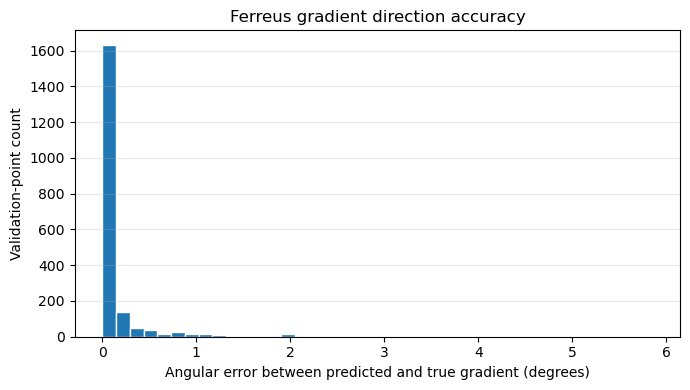

In [14]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(gradient_angle_errors_degrees, bins=40, edgecolor="white")
ax.set_xlabel("Angular error between predicted and true gradient (degrees)")
ax.set_ylabel("Validation-point count")
ax.set_title("Ferreus gradient direction accuracy")
ax.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Geological constraint findings

### Contacts / scalar equality observations

A contact point known to lie on a chosen horizon can be represented as `f(point) = 0`. Both packages accept this because it is an ordinary scalar observation. Multiple horizons require a consistent scheme assigning scalar values to the horizons; choosing those values is part of the geological model, not an RBF package feature.

### Orientation observations

An orientation observation says the field gradient should point in a measured normal direction at a location. Although Ferreus can **calculate** a gradient from an already fitted scalar field, version 0.2.2 does not expose gradient/derivative observations in its public Python fitting constructor. Therefore native orientation-constraint support does not appear to exist.

A possible workaround is to add two scalar pseudo-points a small distance on opposite sides of the orientation location along its normal, with slightly lower/higher scalar values. This approximates a directional derivative using finite differences. It would require deliberate choices for point separation and value offset, weighting relative to contacts, conflict handling, and geological validation. It is a small prototype in code but a non-trivial modelling investigation.

### Exclusion / inequality observations

An inequality says a point must be on one side of a horizon, for example `f(point) > 0`, without specifying the exact field value. Neither public constructor accepts inequalities. A basic workaround would convert the inequality to a pseudo-value with a chosen margin, fit, identify violated points, and iteratively update active pseudo-observations. That is an optimization loop built around the interpolator and is materially more work than ordinary fitting. It also needs tests for convergence, contradictory constraints, and sensitivity to the arbitrary margin.

If one wanted to pursue workaround ideas, the correct next step is a separate, small synthetic experiment with a known expected surface.

## 7. Limitations/next steps

- Test smoothing/noisy observations and additional matched kernels.
- Peak memory and larger-N (up to 16,000) runtime are now measured in section 3.1; extend further if production datasets routinely exceed that size, watching for the point where SciPy's dense O(N^2) memory or O(N^3) fit time becomes impractical on the target machine.
- Add holdout or cross-validation tests on a real geoscience dataset. Real data has no exact field, so withheld-observation error is more defensible than visual agreement alone.
- Test Ferreus global trend / anisotropy behavior.
- If desired, prototype orientation pseudo-points separately, then quantify whether they improve known synthetic orientations without distorting contacts.
- Prototype an active-set inequality wrapper if the additional modelling and maintenance cost is deemed to be worthwhile.
